# Ames House Prices — Final Notebook

We bring together V1's complete data-reading, EDA, cleaning and Ridge baseline
workflow with the final V8 prediction recipe.

**Recorded V8 Kaggle log-RMSE: 0.11101.**

The V1 part trains Ridge from raw data. The V8 part combines fitted-model
predictions saved in final_versions/components/ and applies the frozen
sale-condition and comparable-sale rules. Those branches used their own
preprocessing. The V1 features below support the baseline comparison and do not
replace the inputs used by the already fitted V8 branches.
The repository does not include full retraining code for every V8 component.

## Run
1. Open this notebook inside a clone of this repository.
2. Install requirements-v1.txt in the selected Python kernel:
   python -m pip install -r requirements-v1.txt
3. Run all cells in order. No downloads are performed by the notebook.

The final file is **final_outputs/submission_final.csv**.
The baseline is saved separately as submission_ridge_baseline.csv.
All 1,460 labelled houses and 1,459 test houses are retained.

Source snapshot: [32ed985](https://github.com/onoizu/ames-house-price-prediction/tree/32ed9850223b1a3400de7b576ecc1c20db4fbb9b).

## 1. Import libraries

In [1]:
from pathlib import Path
from time import perf_counter
from hashlib import sha256
from io import BytesIO, StringIO
import csv
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from threadpoolctl import threadpool_limits

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_columns", 12)

## 2. Read and check the data
We preserve the literal category "None". Only blank cells and "NA" are read
as missing values. We also locate the final prediction files before starting.

In [2]:
current = Path.cwd()
root_candidates = list(dict.fromkeys([current, current / "Proj", *current.parents]))
REPO_ROOT = next((
    p for p in root_candidates
    if (p / "Dataset/train.csv").is_file()
    and (p / "final_versions/components").is_dir()
), None)
if REPO_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook inside the repository with Dataset/ and "
        "final_versions/components/ present. On Kaggle, attach these "
        "repository files with the same folder structure."
    )
DATA_DIR = REPO_ROOT / "Dataset"
COMPONENTS = REPO_ROOT / "final_versions/components"
SUBMISSIONS = REPO_ROOT / "final_versions/submissions"
OUTPUT_DIR = REPO_ROOT / "final_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
SOURCE_COMMIT = "32ed9850223b1a3400de7b576ecc1c20db4fbb9b"
VERSION_FILES = {"V5": "v5.csv", "V6": "v6.csv", "V7": "v7.csv", "V8": "v8.csv"}
required_components = [
    "v5_stacked_log_predictions.csv", "v5_svm_predictions.csv",
    "submission_experiment_01.csv", "v7_tabicl_log_predictions.csv",
    "v7_kumo_log_predictions.csv",
]
required_paths = (
    [COMPONENTS / name for name in required_components]
    + [SUBMISSIONS / name for name in VERSION_FILES.values()]
)
missing_files = [str(p.relative_to(REPO_ROOT)) for p in required_paths if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Missing repository files: " + ", ".join(missing_files))

train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False, na_values=["", "NA"])
print("Train:", train.shape, "Test:", test.shape)
display(train.head())

Train: (1460, 81) Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,...,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,...,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,...,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,...,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,...,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,...,0,12,2008,WD,Normal,250000


In [3]:
train.info()
data_checks = pd.Series({
    "Training rows": len(train), "Test rows": len(test),
    "Duplicate training IDs": int(train["Id"].duplicated().sum()),
    "Duplicate test IDs": int(test["Id"].duplicated().sum()),
    "Missing target values": int(train["SalePrice"].isna().sum()),
    "Non-positive targets": int((train["SalePrice"] <= 0).sum()),
})
display(data_checks.to_frame("Value"))
assert train.shape == (1460, 81) and test.shape == (1459, 80)
assert train["Id"].is_unique and test["Id"].is_unique
assert set(train["Id"]).isdisjoint(test["Id"])
assert "SalePrice" not in test.columns
assert train["SalePrice"].notna().all() and train["SalePrice"].gt(0).all()
def frame_fingerprint(frame):
    return sha256(pd.util.hash_pandas_object(frame, index=True).values.tobytes()).hexdigest()
raw_fingerprints = {"train": frame_fingerprint(train), "test": frame_fingerprint(test)}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Value
Training rows,1460
Test rows,1459
Duplicate training IDs,0
Duplicate test IDs,0
Missing target values,0
Non-positive targets,0


## 3. Explore the data
### Price distribution
We plot the original and log-transformed prices before fitting a model.
The competition uses log-RMSE, so lower values are better.

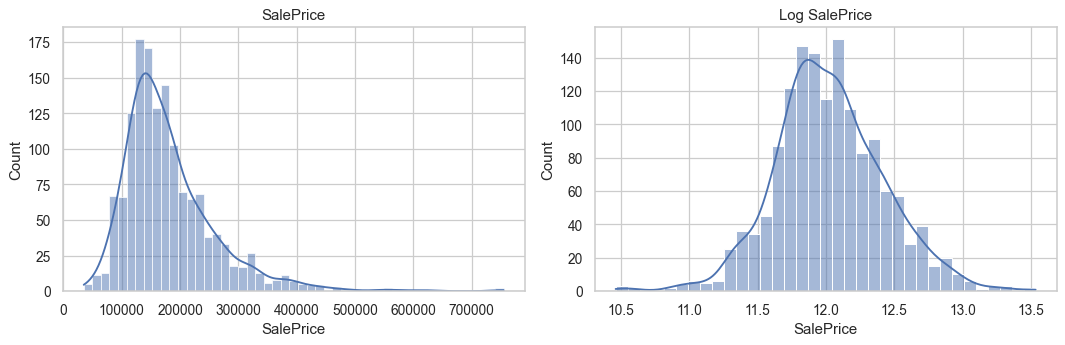

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice")
sns.histplot(np.log(train["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("Log SalePrice")
plt.tight_layout()
plt.show()

### Missing values

A high missing rate does not always mean that a column is useless. For example, PoolQC can be missing because the house has no pool.

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
MasVnrType         8
Electrical         1
dtype: int64


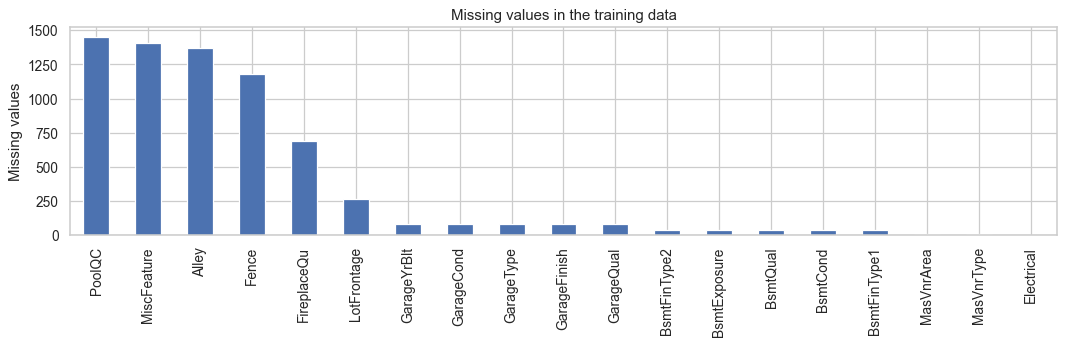

In [5]:
missing = train.isna().sum().sort_values(ascending=False)
print(missing[missing > 0])

missing[missing > 0].plot(kind="bar", figsize=(12, 4))
plt.ylabel("Missing values")
plt.title("Missing values in the training data")
plt.tight_layout()
plt.show()

### Relationships with price

Look at living area, overall quality, and neighborhood. Large houses with low prices are worth checking, but we keep them in this first version.

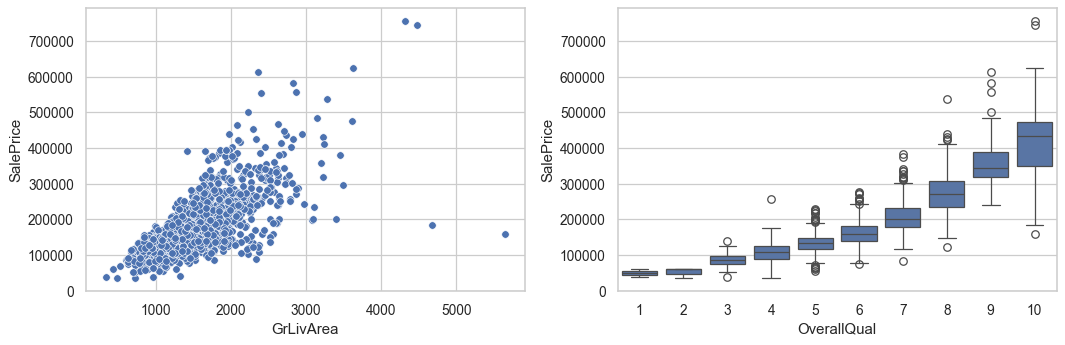

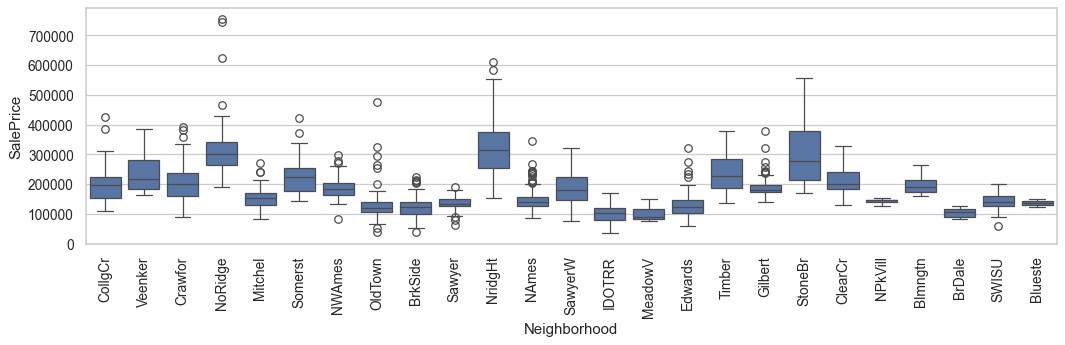

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", ax=axes[0])
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1])
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### Correlation

Show the full correlation matrix for numeric measurements and SalePrice. Exclude Id and the category codes MSSubClass and MoSold.
A larger figure helps us see relationships between features, including possible redundancy. Correlation does not prove causation.

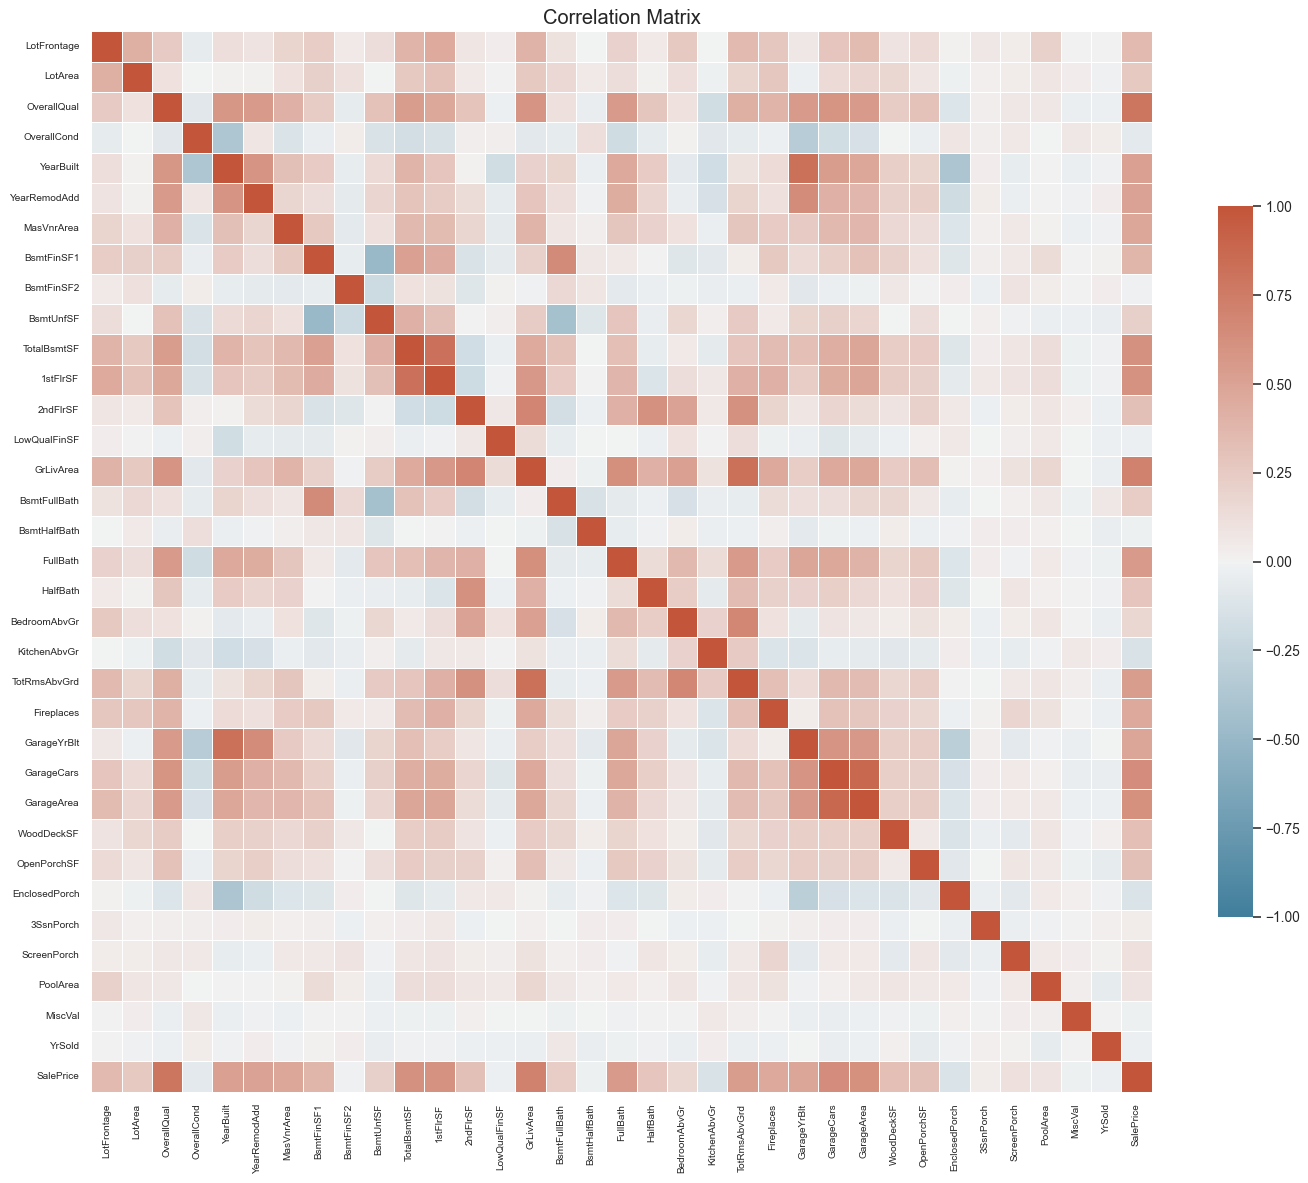

In [7]:
corr = train.drop(columns=["Id", "MSSubClass", "MoSold"]).select_dtypes(include=np.number).corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap=sns.diverging_palette(230, 20, as_cmap=True),
            center=0, vmin=-1, vmax=1, square=True, annot=False,
            linewidths=0.5, cbar_kws={"shrink": 0.6})
plt.title("Correlation Matrix", fontsize=16)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

## 4. Clean the data

Id is not a predictor. We join the feature rows to apply the same fixed cleaning rules to train and test.
Medians, modes, encoding categories, and scaling are learned later from the training split only.

In [8]:
y = np.log(train["SalePrice"])
test_ids = test["Id"].copy()

train_features = train.drop(columns=["Id", "SalePrice"])
test_features = test.drop(columns="Id")
data = pd.concat([train_features, test_features], ignore_index=True)

### Missing facilities and invalid years
We retain V1's simple rules: missing facility categories become "None"
and missing facility amounts become zero. This is an assumption that
can treat some incomplete records as absence.
Missing MasVnrType remains "Unknown".

MSSubClass and MoSold are category codes. Years stay numerical.
These inputs train the Ridge baseline; the saved V8 branches keep
the preprocessing used to generate their own predictions.

In [9]:
none_columns = ["Alley", "Fence", "MiscFeature", "PoolQC", "FireplaceQu",
                "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
for col in none_columns:
    data[col] = data[col].fillna("None")

data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

zero_columns = ["GarageArea", "GarageCars", "TotalBsmtSF", "BsmtFinSF1",
                "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]
for col in zero_columns:
    data[col] = data[col].fillna(0)

for col in ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]:
    invalid_year = (data[col] < 1800) | (data[col] > data["YrSold"] + 1)
    print(col, "invalid years:", invalid_year.sum())
    data.loc[invalid_year, col] = np.nan

data["MSSubClass"] = data["MSSubClass"].astype(str)
data["MoSold"] = data["MoSold"].astype(str)

# Save the original column names for a feature-engineering comparison.
base_columns = data.columns.tolist()

YearBuilt invalid years: 0
YearRemodAdd invalid years: 1
GarageYrBlt invalid years: 1


## 5. Feature engineering

We add only six features:
- TotalSF: basement area + first-floor area + second-floor area.
- TotalBath: full bathrooms + half of the half bathrooms, including the basement.
- HouseAge: years between construction and sale.
- RemodelAge: years since the last remodel.
- HasGarage and HasBasement: whether these facilities exist.

These features may help a linear model capture size, age, and facility effects. They may also repeat information already in the original columns.
We will compare Ridge with and without them instead of assuming more features are better.

In [10]:
data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
data["TotalBath"] = (data["FullBath"] + 0.5 * data["HalfBath"]
                     + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"])
# Clip small negative ages to zero for houses sold around their construction year.
data["HouseAge"] = (data["YrSold"] - data["YearBuilt"]).clip(lower=0)
data["RemodelAge"] = (data["YrSold"] - data["YearRemodAdd"]).clip(lower=0)
data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
data["HasBasement"] = (data["TotalBsmtSF"] > 0).astype(int)

new_columns = ["TotalSF", "TotalBath", "HouseAge", "RemodelAge", "HasGarage", "HasBasement"]
data[new_columns].head()

,TotalSF,TotalBath,HouseAge,RemodelAge,HasGarage,HasBasement
0,2566.0,3.5,5.0,5.0,1,1
1,2524.0,2.5,31.0,31.0,1,1
2,2706.0,3.5,7.0,6.0,1,1
3,2473.0,2.0,91.0,36.0,1,1
4,3343.0,3.5,8.0,8.0,1,1


### Log-transform area features

Apply log1p to selected non-negative area columns to reduce the effect of very large values. log1p also handles zero.
Area totals are calculated before this transformation. The same transformations are used in both Ridge comparisons.

In [11]:
log_columns = ["LotArea", "GrLivArea", "TotalBsmtSF", "1stFlrSF",
               "2ndFlrSF", "MasVnrArea", "TotalSF"]
for col in log_columns:
    data[col] = np.log1p(data[col])

## 6. Prepare a validation set

Use the same 80/20 split for both feature sets. Fill remaining numeric values with training medians and categorical values with training modes, then apply one-hot encoding.
Unknown validation categories become all-zero dummy values.

In [12]:
X = data.iloc[:len(train)].copy()
X_test = data.iloc[len(train):].copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

medians = X_train.median(numeric_only=True)
modes = X_train.select_dtypes(include="object").mode().iloc[0]
X_train = X_train.fillna(medians).fillna(modes)
X_valid = X_valid.fillna(medians).fillna(modes)

# Identify the baseline columns before encoding adds dummy columns.
X_train_base = pd.get_dummies(X_train[base_columns], dtype=int)
X_valid_base = pd.get_dummies(X_valid[base_columns], dtype=int)
X_valid_base = X_valid_base.reindex(columns=X_train_base.columns, fill_value=0)

X_train = pd.get_dummies(X_train, dtype=int)
X_valid = pd.get_dummies(X_valid, dtype=int)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Remaining missing values:", X_train.isna().sum().sum(), X_valid.isna().sum().sum())

Training: (1168, 332)
Validation: (292, 332)
Remaining missing values: 0 0


### Scale the features

Scale the features before fitting Ridge so that their units do not determine the strength of the penalty.
Fit each scaler on the training split and apply it to the validation split.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

base_scaler = StandardScaler()
X_train_base_scaled = base_scaler.fit_transform(X_train_base)
X_valid_base_scaled = base_scaler.transform(X_valid_base)

## 7. Compare Ridge with and without the new features

Keep the model, split, cleaning, and transformations fixed. Record validation error, fitting time, and feature count.
A lower log-RMSE is better. A small change on one split is not strong evidence; later versions can check it with cross-validation.

In [14]:
def fit_ridge_reference(training_matrix, target, prediction_matrix):
    # Same Ridge objective as V1, with a tightly converged LSQR solver.
    assert np.isfinite(training_matrix).all()
    assert np.isfinite(prediction_matrix).all() and np.isfinite(target).all()
    model = Ridge(alpha=10, solver="lsqr", tol=1e-10, max_iter=10000)
    start = perf_counter()
    with threadpool_limits(limits=1):
        model.fit(training_matrix, target)
        # Equivalent to predict(); avoids local BLAS warning flags.
        prediction = (prediction_matrix * model.coef_).sum(axis=1) + model.intercept_
    assert model.n_iter_[0] < model.max_iter
    assert np.isfinite(model.coef_).all()
    assert np.isfinite(prediction).all()
    return model, prediction, perf_counter() - start

ridge_base, base_pred, base_time = fit_ridge_reference(
    X_train_base_scaled, y_train, X_valid_base_scaled)
ridge, ridge_pred, ridge_time = fit_ridge_reference(
    X_train_scaled, y_train, X_valid_scaled)
base_score = np.sqrt(mean_squared_error(y_valid, base_pred))
ridge_score = np.sqrt(mean_squared_error(y_valid, ridge_pred))
feature_comparison = pd.DataFrame({
    "Features": ["Original", "Original + 6 new features"],
    "Validation log-RMSE": [base_score, ridge_score],
    "Fit seconds": [base_time, ridge_time],
    "Feature count": [X_train_base.shape[1], X_train.shape[1]],
})
feature_comparison.to_csv(OUTPUT_DIR / "ridge_feature_comparison.csv", index=False)
display(feature_comparison)

,Features,Validation log-RMSE,Fit seconds,Feature count
0,Original,0.124284,0.028358,326
1,Original + 6 new features,0.123827,0.013219,332


## 8. Choose the feature set and check prediction errors

Keep the feature set with the lower validation log-RMSE. Both choices use the same Ridge model and alpha=10.
Since this validation set is used for selection, its score is not an independent final test score.

Model: Ridge (alpha=10)
Selected features: Original + 6 new features


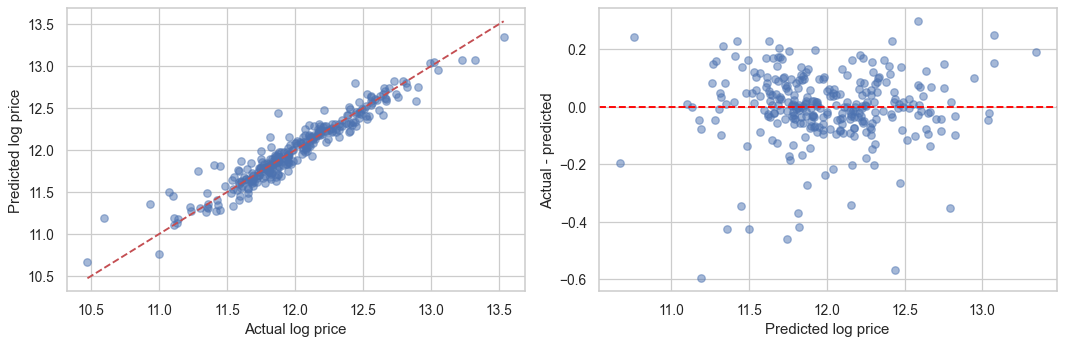

In [15]:
if ridge_score < base_score:
    selected_features = "Original + 6 new features"
    best_valid_pred = ridge_pred
else:
    selected_features = "Original"
    best_valid_pred = base_pred

print("Model: Ridge (alpha=10)")
print("Selected features:", selected_features)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_valid, best_valid_pred, alpha=0.5)
axes[0].plot([y_valid.min(), y_valid.max()], [y_valid.min(), y_valid.max()], "r--")
axes[0].set(xlabel="Actual log price", ylabel="Predicted log price")
axes[1].scatter(best_valid_pred, y_valid - best_valid_pred, alpha=0.5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Predicted log price", ylabel="Actual - predicted")
plt.tight_layout()
plt.show()

## 9. Refit the selected Ridge baseline
We recalculate medians, modes, dummy columns and scaling using all labelled
rows, then refit Ridge. Test data never supplies these statistics.

In [16]:
medians = X.median(numeric_only=True)
modes = X.select_dtypes(include="object").mode().iloc[0]
X_full = X.fillna(medians).fillna(modes)
X_test_full = X_test.fillna(medians).fillna(modes)

if selected_features == "Original":
    X_full = X_full[base_columns]
    X_test_full = X_test_full[base_columns]

X_full = pd.get_dummies(X_full, dtype=int)
X_test_full = pd.get_dummies(X_test_full, dtype=int)
X_test_full = X_test_full.reindex(columns=X_full.columns, fill_value=0)

scaler = StandardScaler()
X_full_scaled = scaler.fit_transform(X_full)
X_test_scaled = scaler.transform(X_test_full)

final_ridge, test_pred_log, full_fit_seconds = fit_ridge_reference(
    X_full_scaled, y, X_test_scaled
)

## 10. Save the baseline prediction

In [17]:
ridge_submission = pd.DataFrame({"Id": test_ids, "SalePrice": np.exp(test_pred_log)})
assert len(ridge_submission) == len(test) and ridge_submission["Id"].equals(test["Id"])
assert np.isfinite(ridge_submission["SalePrice"]).all()
assert ridge_submission["SalePrice"].gt(0).all()
ridge_path = OUTPUT_DIR / "submission_ridge_baseline.csv"
ridge_submission.to_csv(ridge_path, index=False)
print("Selected features:", selected_features)
print(f"Holdout log-RMSE: {min(base_score, ridge_score):.6f}")
print("Baseline saved:", ridge_path.relative_to(REPO_ROOT))
display(ridge_submission.head().round(2))

Selected features: Original + 6 new features
Holdout log-RMSE: 0.123827
Baseline saved: final_outputs/submission_ridge_baseline.csv


,Id,SalePrice
0,1461,120785.20
1,1462,174191.86
2,1463,185991.38
3,1464,204877.29
4,1465,196631.13


## 11. Assemble the frozen V8 prediction pipeline
We now use the saved model predictions. The functions below are included
directly from final_versions/rebuild.py, so no separate project Python module
is imported. They preserve the recorded transformations, tail adjustments,
log-price blends and comparable-sale rule.

The first branch retains the original expm1(sqrt(...)) transformation exactly.
No parameters or rules are re-tuned using this notebook's holdout results.
The Ridge holdout score and Kaggle score are different evaluation settings.

In [18]:
def read_component(name, column, expected_ids):
    frame = pd.read_csv(COMPONENTS / name)
    if not frame["Id"].equals(expected_ids):
        raise ValueError(f"{name} has different house IDs or row order")
    values = frame[column].to_numpy()
    if not np.isfinite(values).all() or not (values > 0).all():
        raise ValueError(f"{name} has invalid predictions")
    return values

def encode_prices(ids, prices):
    return pd.DataFrame({"Id": ids, "SalePrice": prices}).to_csv(index=False).encode("utf-8")

def read_prices(payload):
    return pd.read_csv(BytesIO(payload))["SalePrice"].to_numpy()

def rebuild_v5(ids):
    stack = read_component("v5_stacked_log_predictions.csv", "stacked_log_prediction", ids)
    svm = read_component("v5_svm_predictions.csv", "SalePrice", ids)
    raw = np.expm1(np.sqrt(stack * np.log(svm)))
    low, high = np.quantile(raw, [0.0042, 0.99])
    adjusted = raw.copy()
    adjusted[raw <= low] *= 0.77
    adjusted[raw >= high] *= 1.10
    return encode_prices(ids, adjusted)

def rebuild_v6(ids, v5):
    experiment = read_component("submission_experiment_01.csv", "SalePrice", ids)
    prices = np.exp(0.5 * np.log(read_prices(v5)) + 0.5 * np.log(experiment))
    return encode_prices(ids, prices)

def rebuild_v7(test, v6):
    ids = test["Id"]
    normal = test["SaleCondition"].eq("Normal").to_numpy()
    tabicl = read_component("v7_tabicl_log_predictions.csv", "prediction_log", ids)
    kumo = read_component("v7_kumo_log_predictions.csv", "log_price", ids)
    prices = read_prices(v6).copy()
    intermediate = prices.copy()
    intermediate[normal] = np.exp(0.75 * np.log(prices[normal]) + 0.25 * tabicl[normal])
    # The scored run wrote and reloaded the TabICL blend before adding Kumo.
    intermediate = read_prices(encode_prices(ids, intermediate))
    prices[normal] = np.exp(0.25 * np.log(intermediate[normal]) + 0.75 * kumo[normal])
    return encode_prices(ids, prices)

def large_partial_new_sales(frame):
    age = frame["YrSold"] - frame["YearBuilt"]
    return (
        frame["SaleCondition"].eq("Partial")
        & frame["SaleType"].eq("New")
        & frame["GrLivArea"].gt(4000)
        & age.between(-1, 1)
    )

def rebuild_v8(train, test, v7):
    candidates = train.loc[large_partial_new_sales(train)]
    base = read_prices(v7)
    prices_by_id = {}
    for i in np.flatnonzero(large_partial_new_sales(test).to_numpy()):
        row = test.iloc[i]
        similar = candidates[
            candidates["Neighborhood"].eq(row["Neighborhood"])
            & candidates["BldgType"].eq(row["BldgType"])
            & candidates["OverallQual"].sub(row["OverallQual"]).abs().le(1)
            & np.log(candidates["GrLivArea"] / row["GrLivArea"]).abs().le(0.25)
            & np.log(candidates["LotArea"] / row["LotArea"]).abs().le(0.60)
        ]
        if similar.empty:
            continue
        reference = np.median(np.log(similar["SalePrice"].to_numpy()))
        estimate = np.exp(0.5 * np.log(base[i]) + 0.5 * reference)
        prices_by_id[str(row["Id"])] = f"{estimate:.8f}"

    output = StringIO()
    writer = csv.DictWriter(output, fieldnames=["Id", "SalePrice"], lineterminator="\n")
    writer.writeheader()
    for row in csv.DictReader(StringIO(v7.decode("utf-8"))):
        row["SalePrice"] = prices_by_id.get(row["Id"], row["SalePrice"])
        writer.writerow(row)
    return output.getvalue().encode("utf-8")

In [19]:
verification_rows = []
def check_recorded_prediction(version, payload):
    expected_path = SUBMISSIONS / VERSION_FILES[version]
    expected = pd.read_csv(expected_path)
    actual = pd.read_csv(BytesIO(payload))
    assert actual.columns.tolist() == ["Id", "SalePrice"]
    assert actual["Id"].equals(test["Id"]) and expected["Id"].equals(test["Id"])
    assert actual["Id"].is_unique and len(actual) == len(test)
    assert np.isfinite(actual["SalePrice"]).all() and actual["SalePrice"].gt(0).all()
    np.testing.assert_allclose(
        actual["SalePrice"], expected["SalePrice"], rtol=1e-12, atol=1e-7,
        err_msg=f"{version} differs from the frozen scored predictions")
    verification_rows.append({
        "Stage": version, "Rows": len(actual),
        "Maximum price difference": float(np.max(np.abs(
            actual["SalePrice"].to_numpy() - expected["SalePrice"].to_numpy()))),
        "Numerically matched": True,
        "Byte-identical": payload == expected_path.read_bytes(),
    })
    return actual

### 11.1 Combine the stacking/SVM outputs and adjust the tails
The frozen rule reduces the lowest 0.42% tail by 23% and increases the highest
1% tail by 10%. These adjustments belong to the scored pipeline.

In [20]:
v5_payload = rebuild_v5(test["Id"])
v5_prices = check_recorded_prediction("V5", v5_payload)
stack_log = read_component("v5_stacked_log_predictions.csv", "stacked_log_prediction", test["Id"])
svm_price = read_component("v5_svm_predictions.csv", "SalePrice", test["Id"])
before_tail = np.expm1(np.sqrt(stack_log * np.log(svm_price)))
low, high = np.quantile(before_tail, [0.0042, 0.99])
display(pd.DataFrame({
    "Adjustment": ["Lower tail x 0.77", "Higher tail x 1.10"],
    "Houses": [int((before_tail <= low).sum()), int((before_tail >= high).sum())],
}))

,Adjustment,Houses
0,Lower tail x 0.77,7
1,Higher tail x 1.10,15


### 11.2 Add the SVR/CatBoost correction pipeline
We combine its saved predictions with the preceding output using equal
weights on the log-price scale.

In [21]:
v6_payload = rebuild_v6(test["Id"], v5_payload)
v6_prices = check_recorded_prediction("V6", v6_payload)
display(v6_prices.head().round(2))

,Id,SalePrice
0,1461,121755.31
1,1462,163700.14
2,1463,185220.03
3,1464,197044.14
4,1465,189088.16


### 11.3 Combine TabICLv2 and Kumo for normal sales
The effective log-price weights are 18.75% for the preceding blend,
6.25% for TabICLv2 and 75% for the saved mean of the two Kumo branches.
Other sale conditions retain their preceding predictions.

In [22]:
v7_payload = rebuild_v7(test, v6_payload)
v7_prices = check_recorded_prediction("V7", v7_payload)
normal_sales = test["SaleCondition"].eq("Normal")
np.testing.assert_allclose(
    v7_prices.loc[~normal_sales, "SalePrice"],
    v6_prices.loc[~normal_sales, "SalePrice"], rtol=1e-12, atol=1e-7)
display(pd.DataFrame({
    "Sale group": ["Normal", "Other conditions"],
    "Houses": [int(normal_sales.sum()), int((~normal_sales).sum())],
    "Prediction": ["Expanded blend", "Preceding blend"],
}))

,Sale group,Houses,Prediction
0,Normal,1204,Expanded blend
1,Other conditions,255,Preceding blend


## 12. Apply the final comparable-sale rule
We check large new houses marked Partial, meaning incomplete when last
assessed. Training comparables must have the same neighbourhood and building
type, similar quality and similar living and lot areas. The rule combines
the preceding log estimate with the median log price of the comparables.
No hidden test prices are used.

In [23]:
v8_payload = rebuild_v8(train, test, v7_payload)
final_submission = check_recorded_prediction("V8", v8_payload)
case_comparison = pd.DataFrame({
    "Id": test["Id"], "Before comparable adjustment": v7_prices["SalePrice"],
    "Final V8 price": final_submission["SalePrice"],
})
changed = ~np.isclose(
    case_comparison["Before comparable adjustment"], case_comparison["Final V8 price"],
    rtol=1e-12, atol=1e-7)
print("Houses changed by the final rule:", int(changed.sum()))
display(case_comparison.loc[changed].round(2))
candidate_sales = train.loc[large_partial_new_sales(train)]
comparable_records = []
for i in np.flatnonzero(changed):
    house = test.iloc[i]
    similar = candidate_sales[
        candidate_sales["Neighborhood"].eq(house["Neighborhood"])
        & candidate_sales["BldgType"].eq(house["BldgType"])
        & candidate_sales["OverallQual"].sub(house["OverallQual"]).abs().le(1)
        & np.log(candidate_sales["GrLivArea"] / house["GrLivArea"]).abs().le(0.25)
        & np.log(candidate_sales["LotArea"] / house["LotArea"]).abs().le(0.60)]
    for _, row in similar.iterrows():
        comparable_records.append({
            "Test Id": int(house["Id"]), "Comparable train Id": int(row["Id"]),
            "Living area": row["GrLivArea"], "Lot area": row["LotArea"],
            "Quality": row["OverallQual"], "Known training price": row["SalePrice"],
        })
comparable_audit = pd.DataFrame(comparable_records)
display(comparable_audit)

Houses changed by the final rule: 1


,Id,Before comparable adjustment,Final V8 price
1089,2550,339331.06,241539.36


,Test Id,Comparable train Id,Living area,Lot area,Quality,Known training price
0,2550,524,4676,40094,10,184750
1,2550,1299,5642,63887,10,160000


## 13. Verify and export the final submission
We check identifiers, row counts and finite positive prices before exporting.
Numerical matching permits tiny floating-point differences across environments;
byte identity additionally requires identical CSV text.
The score 0.11101 is a recorded Kaggle result, not a new local validation score.

In [24]:
assert frame_fingerprint(train) == raw_fingerprints["train"]
assert frame_fingerprint(test) == raw_fingerprints["test"]
assert len(final_submission) == 1459 and final_submission["Id"].is_unique
assert final_submission["SalePrice"].notna().all()
assert np.isfinite(final_submission["SalePrice"]).all()
assert final_submission["SalePrice"].gt(0).all()
final_path = OUTPUT_DIR / "submission_final.csv"
final_path.write_bytes(v8_payload)
verification = pd.DataFrame(verification_rows)
verification.to_csv(OUTPUT_DIR / "final_prediction_checks.csv", index=False)
case_comparison.loc[changed].to_csv(OUTPUT_DIR / "comparable_adjustments.csv", index=False)
comparable_audit.to_csv(OUTPUT_DIR / "comparable_training_sales.csv", index=False)
display(verification)
print("Final submission:", final_path.relative_to(REPO_ROOT))
print("Recorded V8 Kaggle log-RMSE: 0.11101")
display(final_submission.head().round(2))

,Stage,Rows,Maximum price difference,Numerically matched,Byte-identical
0,V5,1459,9.313226e-10,True,False
1,V6,1459,8.731149e-10,True,False
2,V7,1459,1.862645e-09,True,False
3,V8,1459,1.862645e-09,True,False


Final submission: final_outputs/submission_final.csv
Recorded V8 Kaggle log-RMSE: 0.11101


,Id,SalePrice
0,1461,122413.87
1,1462,161599.65
2,1463,187559.05
3,1464,198818.62
4,1465,182330.24


## 14. Save a run record
We record source, input hashes, software versions and final checks.

In [25]:
package_names = ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn"]
run_record = {
    "source_commit": SOURCE_COMMIT, "python": platform.python_version(),
    "packages": {name: importlib.metadata.version(name) for name in package_names},
    "training_rows": len(train), "test_rows": len(test),
    "ridge_selected_features": selected_features,
    "ridge_holdout_log_rmse": float(min(base_score, ridge_score)),
    "recorded_v8_kaggle_log_rmse": 0.11101,
    "v8_component_retraining": False,
    "changed_test_houses": int(changed.sum()),
    "all_recorded_stages_matched": bool(verification["Numerically matched"].all()),
    "input_sha256": {
        str(path.relative_to(REPO_ROOT)): sha256(path.read_bytes()).hexdigest()
        for path in [DATA_DIR / "train.csv", DATA_DIR / "test.csv", *required_paths]},
    "final_submission_sha256": sha256(v8_payload).hexdigest(),
}
(OUTPUT_DIR / "run_manifest_final.json").write_text(
    json.dumps(run_record, indent=2) + "\n", encoding="utf-8")
print("Saved run_manifest_final.json")

Saved run_manifest_final.json


## References and source files
- [Kaggle competition](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)
- [V1 notebook](house_prices_v1.ipynb): data, EDA and baseline workflow.
- [V8 notebook](house_prices_v8.ipynb) and [rebuild recipe](final_versions/rebuild.py).
- [Final component records](final_versions/README.md).
- [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).

Rebuilding the final CSV does not retrain stacking, the R branch, TabICLv2 or Kumo.